# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Anissya Eliviani Aulia
- **Email:** 2407025@itg.ac.id
- **ID Dicoding:** DS367B6X0209

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Pertanyaan 1**

Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam antara hari kerja dan hari nonkerja, serta pada jam berapa penyewaan mencapai puncaknya pada masing-masing jenis hari selama periode Januari 2011 hingga Desember 2012?

**Pertanyaan 2**

Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per hari berdasarkan musim dan kondisi cuaca selama periode Januari 2011 hingga Desember 2012, serta bagaimana hasilnya dapat digunakan untuk merencanakan ketersediaan sepeda?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df ...

In [2]:
hour_df = pd.read_csv("hour.csv")
day_df = pd.read_csv("day.csv")

print("Data penyewaan per jam:")
display(hour_df.head())

print("Data penyewaan per hari:")
display(day_df.head())

Data penyewaan per jam:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Data penyewaan per hari:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:**

1. Dataset penyewaan sepeda per jam memiliki informasi mengenai waktu penyewaan, musim, kondisi cuaca, jenis hari, serta jumlah penyewaan. Kolom `cnt` menunjukkan jumlah total penyewaan sepeda, sedangkan `casual` dan `registered` menunjukkan jumlah penyewaan dari pengguna kasual dan pengguna terdaftar.

2. Dataset penyewaan sepeda per hari memiliki informasi yang serupa, tetapi jumlah penyewaannya dirangkum berdasarkan tanggal. Dengan demikian, dataset ini dapat digunakan untuk menganalisis perbedaan jumlah penyewaan berdasarkan musim dan kondisi cuaca.

3. Berdasarkan lima baris pertama, jumlah penyewaan pada dataset per jam terlihat bervariasi pada setiap jam. Sementara itu, pada dataset per hari, jumlah penyewaan yang terlihat juga berbeda pada setiap tanggal. Namun, diperlukan analisis terhadap keseluruhan data untuk mengetahui pola penyewaan secara lebih akurat.

### Assessing Data

#### Identifying ... problem

In [3]:
print("Informasi data per jam:")
hour_df.info()

print("\nInformasi data per hari:")
day_df.info()

print("\nJumlah data kosong:")
print("hour_df:", hour_df.isna().sum().sum())
print("day_df:", day_df.isna().sum().sum())

print("\nJumlah data duplikat:")
print("hour_df:", hour_df.duplicated().sum())
print("day_df:", day_df.duplicated().sum())

Informasi data per jam:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

Informasi data per hari:

**Steps to Take:**
- Mengubah tipe data pada kolom `dteday` dari `object` menjadi `datetime` agar data tanggal dapat diolah dan dianalisis dengan tepat.
- Memeriksa kembali struktur data, jumlah data kosong, dan data duplikat pada dataset penyewaan sepeda per jam dan per hari sebelum melakukan analisis lebih lanjut.

Insight:

- Dataset penyewaan sepeda per jam memiliki 17.379 baris dan 17 kolom, sedangkan dataset penyewaan sepeda per hari memiliki 731 baris dan 16 kolom.
- Kedua dataset tidak memiliki data kosong maupun baris duplikat, sehingga tidak diperlukan penanganan khusus untuk kedua masalah tersebut berdasarkan hasil pemeriksaan ini.
- Kolom `dteday` pada kedua dataset masih bertipe `object`, sehingga perlu diubah menjadi tipe `datetime` agar dapat digunakan untuk analisis berdasarkan tanggal dan periode waktu.

### Cleaning Data

#### Fixing ... problem

In [4]:
# Mengubah tipe data tanggal menjadi datetime
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])
day_df["dteday"] = pd.to_datetime(day_df["dteday"])

# Memeriksa hasil perubahan
print("Tipe data dteday pada hour_df:", hour_df["dteday"].dtype)
print("Tipe data dteday pada day_df:", day_df["dteday"].dtype)

Tipe data dteday pada hour_df: datetime64[ns]
Tipe data dteday pada day_df: datetime64[ns]


Insight:
- Kolom `dteday` pada dataset penyewaan sepeda per jam dan per hari berhasil diubah dari tipe data `object` menjadi `datetime64[ns]`, sehingga dapat digunakan untuk analisis berdasarkan tanggal dan periode waktu.
- Berdasarkan pemeriksaan sebelumnya, kedua dataset tidak memiliki data kosong maupun data duplikat. Oleh karena itu, tidak diperlukan penghapusan data berdasarkan kedua pemeriksaan tersebut.

## Exploratory Data Analysis (EDA)

### Explore ...

In [5]:
# Menghitung rata-rata penyewaan berdasarkan jam dan jenis hari
hour_comparison = (
    hour_df.groupby(["hr", "workingday"])["cnt"]
    .mean()
    .reset_index()
)

hour_comparison["Jenis Hari"] = hour_comparison["workingday"].map({
    0: "Hari Non-Kerja",
    1: "Hari Kerja"
})

display(hour_comparison.head())

,hr,workingday,cnt,Jenis Hari
0,0,0,90.800000,Hari Non-Kerja
1,0,1,36.786290,Hari Kerja
2,1,0,69.508696,Hari Non-Kerja
3,1,1,16.552632,Hari Kerja
4,2,0,53.171053,Hari Non-Kerja


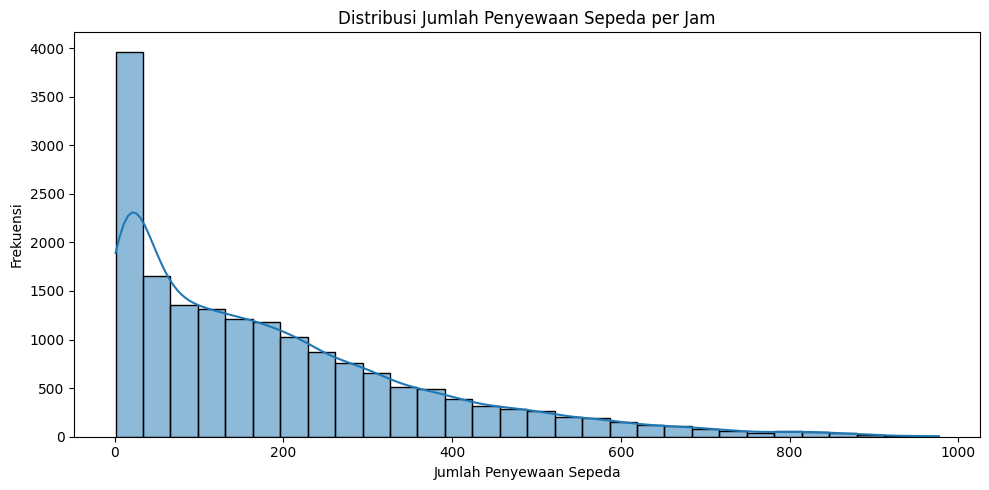

In [6]:
# Distribusi jumlah penyewaan sepeda per jam
plt.figure(figsize=(10, 5))
sns.histplot(data=hour_df, x="cnt", bins=30, kde=True)

plt.title("Distribusi Jumlah Penyewaan Sepeda per Jam")
plt.xlabel("Jumlah Penyewaan Sepeda")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

1.Boxplot — melihat persebaran dan pencilan

Tujuannya untuk melihat persebaran jumlah penyewaan dan kemungkinan adanya nilai pencilan (outlier).

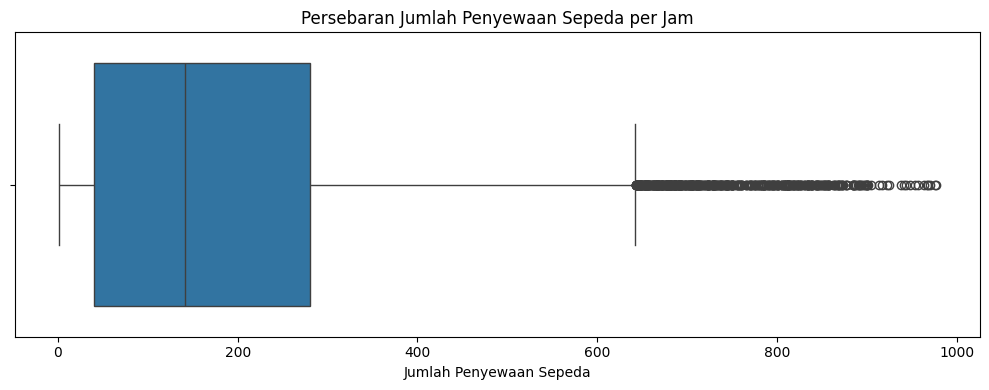

In [7]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=hour_df, x="cnt")

plt.title("Persebaran Jumlah Penyewaan Sepeda per Jam")
plt.xlabel("Jumlah Penyewaan Sepeda")
plt.tight_layout()
plt.show()

2.Analisis kategorikal — hari kerja dan nonkerja

Tujuannya untuk membandingkan karakteristik penyewaan pada hari kerja dan nonkerja melalui statistik, bukan hanya grafik.

In [8]:
workingday_eda = (
    hour_df.groupby("workingday")["cnt"]
    .agg(["count", "mean", "median", "min", "max"])
    .reset_index()
)

workingday_eda["Jenis Hari"] = workingday_eda["workingday"].map({
    0: "Hari Non-Kerja",
    1: "Hari Kerja"
})

display(workingday_eda)

,workingday,count,mean,median,min,max,Jenis Hari
0,0,5514,181.405332,119.0,1,783,Hari Non-Kerja
1,1,11865,193.207754,151.0,1,977,Hari Kerja


3.Analisis numerik — ringkasan statistik

Tujuannya untuk melihat jumlah data, rata-rata, standar deviasi, nilai minimum, median, dan maksimum variabel numerik.

In [9]:
hour_df[["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]].describe()

,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


4.Analisis multivariat — heatmap korelasi

Tujuannya untuk melihat hubungan antarvariabel numerik, seperti suhu, kelembapan, dan jumlah penyewaan.

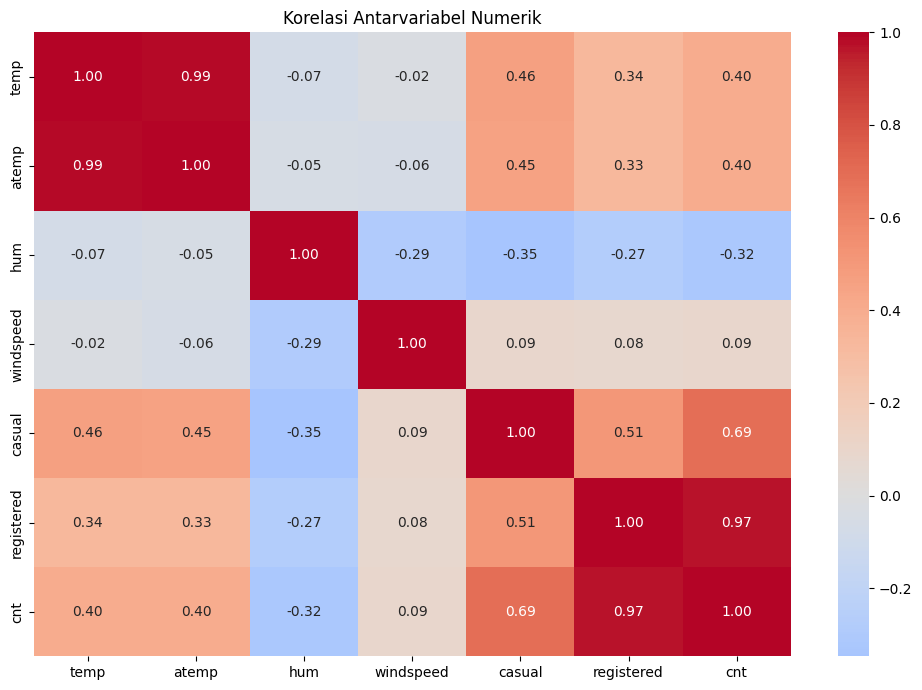

In [10]:
numeric_columns = [
    "temp", "atemp", "hum", "windspeed",
    "casual", "registered", "cnt"
]

correlation = hour_df[numeric_columns].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Korelasi Antarvariabel Numerik")
plt.tight_layout()
plt.show()

Berdasarkan eksplorasi awal, jumlah penyewaan sepeda per jam memiliki variasi yang cukup besar. Analisis statistik berdasarkan jenis hari digunakan untuk memahami perbedaan pola penyewaan pada hari kerja dan hari nonkerja. Selanjutnya, analisis korelasi dilakukan untuk melihat hubungan antarvariabel numerik yang berkaitan dengan jumlah penyewaan.

**Insight:**

- Berdasarkan analisis data penyewaan sepeda selama periode Januari 2011 hingga Desember 2012, rata-rata jumlah penyewaan tertinggi pada hari kerja terjadi pada pukul 17.00, yaitu sebesar 525,29 penyewaan per jam. Sementara itu, pada hari nonkerja, rata-rata jumlah penyewaan tertinggi terjadi pada pukul 13.00, yaitu sebesar 372,73 penyewaan per jam.

- Perbedaan jam puncak tersebut menunjukkan bahwa pola penyewaan sepeda berbeda antara hari kerja dan hari nonkerja. Pada hari kerja, penyewaan mencapai puncaknya pada sore hari, sedangkan pada hari nonkerja puncaknya terjadi pada siang hari. Informasi ini dapat menjadi pertimbangan bagi pengelola untuk menyesuaikan ketersediaan sepeda dengan pola permintaan pada masing-masing jenis hari.

## Visualization & Explanatory Analysis

### Pertanyaan 1:
Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam antara hari kerja dan hari nonkerja, serta pada jam berapa penyewaan mencapai puncaknya pada masing-masing jenis hari selama periode Januari 2011 hingga Desember 2012?

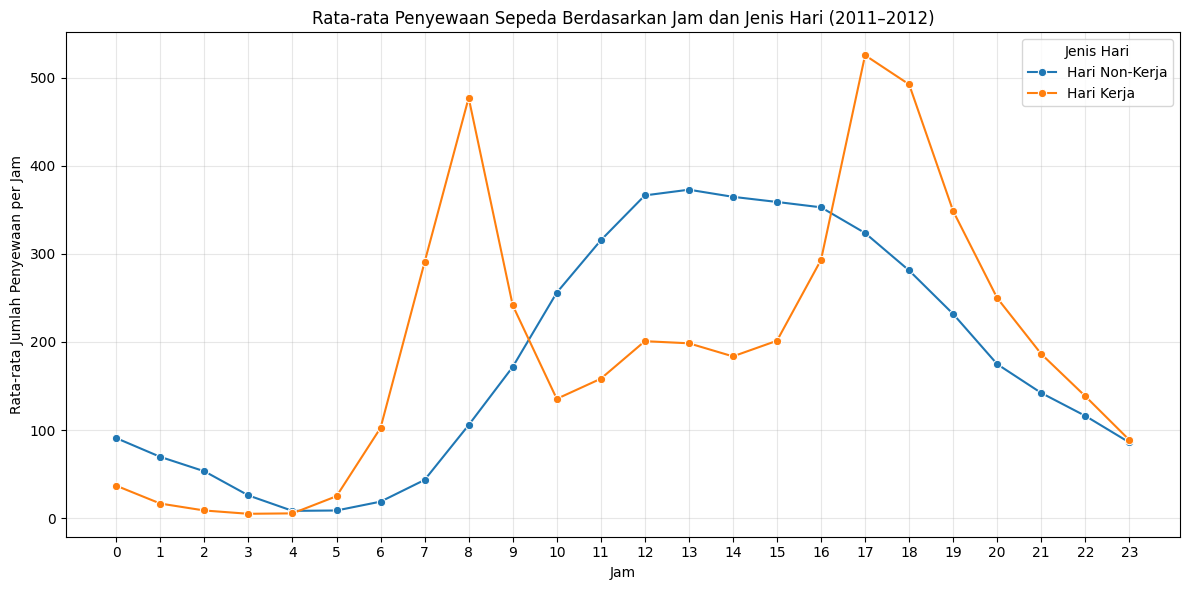

In [11]:
# Pertanyaan 1: Rata-rata penyewaan berdasarkan jam dan jenis hari
hour_comparison = (
    hour_df.groupby(["hr", "workingday"])["cnt"]
    .mean()
    .reset_index()
)

hour_comparison["Jenis Hari"] = hour_comparison["workingday"].map({
    0: "Hari Non-Kerja",
    1: "Hari Kerja"
})

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=hour_comparison,
    x="hr",
    y="cnt",
    hue="Jenis Hari",
    marker="o"
)

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Jam dan Jenis Hari (2011–2012)")
plt.xlabel("Jam")
plt.ylabel("Rata-rata Jumlah Penyewaan per Jam")
plt.xticks(range(24))
plt.legend(title="Jenis Hari")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Pertanyaan 2:
Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per hari berdasarkan musim dan kondisi cuaca selama periode Januari 2011 hingga Desember 2012, serta bagaimana hasilnya dapat digunakan untuk merencanakan ketersediaan sepeda?

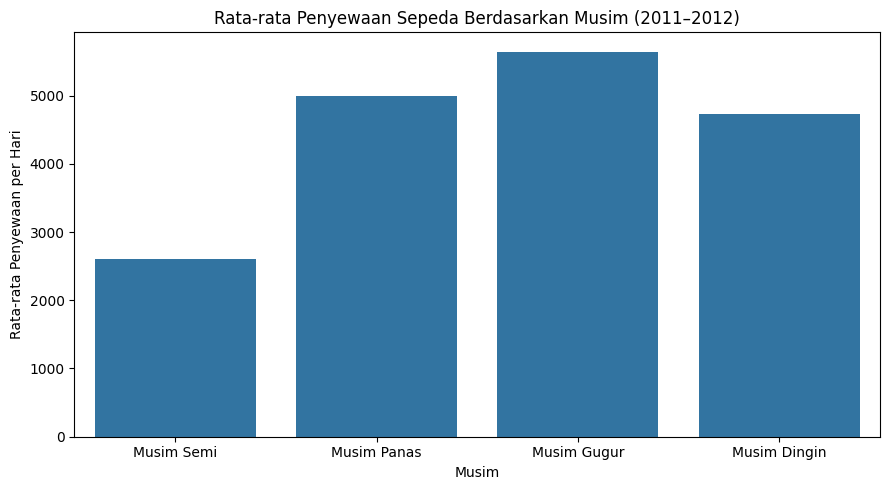

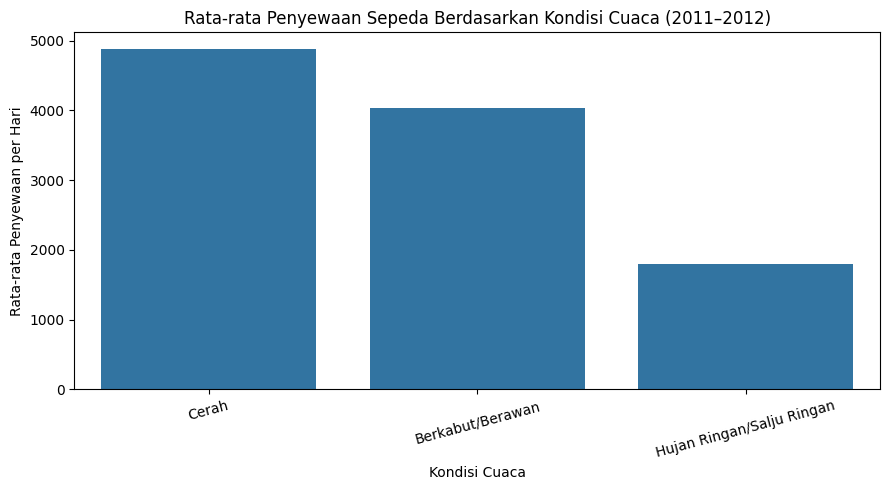

In [12]:
# Pertanyaan 2A: Rata-rata penyewaan berdasarkan musim
season_analysis = (
    day_df.groupby("season")["cnt"]
    .mean()
    .reset_index()
)

season_analysis["Musim"] = season_analysis["season"].map({
    1: "Musim Semi",
    2: "Musim Panas",
    3: "Musim Gugur",
    4: "Musim Dingin"
})

plt.figure(figsize=(9, 5))
sns.barplot(
    data=season_analysis,
    x="Musim",
    y="cnt"
)

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Musim (2011–2012)")
plt.xlabel("Musim")
plt.ylabel("Rata-rata Penyewaan per Hari")
plt.tight_layout()
plt.show()


# Pertanyaan 2B: Rata-rata penyewaan berdasarkan kondisi cuaca
weather_analysis = (
    day_df.groupby("weathersit")["cnt"]
    .mean()
    .reset_index()
)

weather_analysis["Kondisi Cuaca"] = weather_analysis["weathersit"].map({
    1: "Cerah",
    2: "Berkabut/Berawan",
    3: "Hujan Ringan/Salju Ringan"
})

plt.figure(figsize=(9, 5))
sns.barplot(
    data=weather_analysis,
    x="Kondisi Cuaca",
    y="cnt"
)

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca (2011–2012)")
plt.xlabel("Kondisi Cuaca")
plt.ylabel("Rata-rata Penyewaan per Hari")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Insight:
- Berdasarkan analisis periode Januari 2011 hingga Desember 2012, rata-rata penyewaan sepeda pada hari kerja mencapai puncaknya pukul 17.00 sebesar 525,29 penyewaan per jam. Sementara itu, pada hari nonkerja, puncak penyewaan terjadi pukul 13.00 sebesar 372,73 penyewaan per jam. Hasil ini menunjukkan adanya perbedaan pola waktu penyewaan antara kedua jenis hari. Pengelola dapat mempertimbangkan pola tersebut dalam mengatur ketersediaan sepeda.

- Berdasarkan analisis data harian, rata-rata penyewaan tertinggi terjadi pada musim gugur, sebesar 5.644,30 penyewaan per hari, sedangkan rata-rata terendah terjadi pada musim semi, sebesar 2.604,13 penyewaan per hari. Berdasarkan kondisi cuaca, rata-rata penyewaan tertinggi terjadi pada cuaca kategori 1 sebesar 4.876,79 penyewaan per hari, sedangkan kategori 3 memiliki rata-rata terendah sebesar 1.803,29 penyewaan per hari. Temuan ini dapat menjadi pertimbangan dalam merencanakan ketersediaan sepeda berdasarkan musim dan kondisi cuaca.

## Analisis Lanjutan (Opsional)

,workingday,casual,registered,Jenis Hari
0,0,57.441422,123.963910,Hari Non-Kerja
1,1,25.561315,167.646439,Hari Kerja


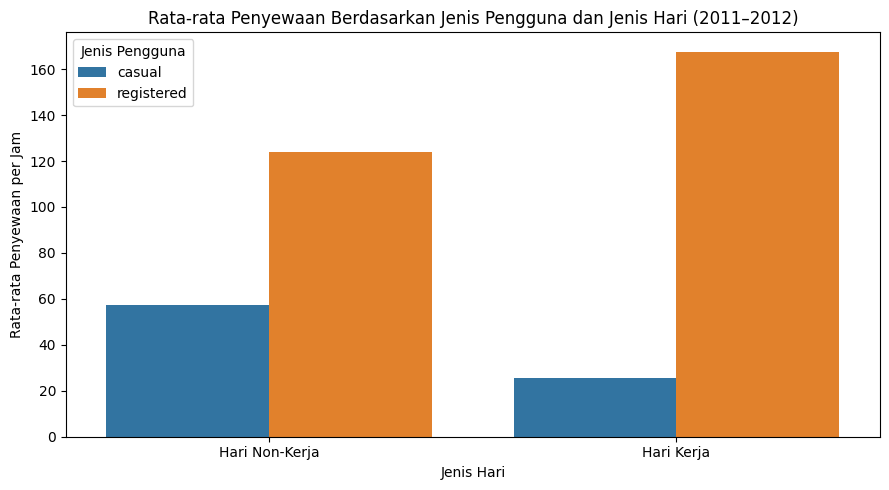

In [13]:
# Analisis rata-rata penyewaan berdasarkan jenis pengguna dan jenis hari
user_analysis = (
    hour_df.groupby("workingday")[["casual", "registered"]]
    .mean()
    .reset_index()
)

user_analysis["Jenis Hari"] = user_analysis["workingday"].map({
    0: "Hari Non-Kerja",
    1: "Hari Kerja"
})

display(user_analysis)

# Mengubah data menjadi format yang sesuai untuk visualisasi
user_comparison = user_analysis.melt(
    id_vars="Jenis Hari",
    value_vars=["casual", "registered"],
    var_name="Jenis Pengguna",
    value_name="Rata-rata Penyewaan"
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=user_comparison,
    x="Jenis Hari",
    y="Rata-rata Penyewaan",
    hue="Jenis Pengguna"
)

plt.title("Rata-rata Penyewaan Berdasarkan Jenis Pengguna dan Jenis Hari (2011–2012)")
plt.xlabel("Jenis Hari")
plt.ylabel("Rata-rata Penyewaan per Jam")
plt.tight_layout()
plt.show()

Insight:
- Analisis lanjutan dilakukan untuk membandingkan rata-rata penyewaan sepeda oleh pengguna kasual dan pengguna terdaftar pada hari kerja dan hari nonkerja selama periode 2011–2012.
- Hasil analisis ini dapat membantu pengelola memahami perbedaan pola penggunaan sepeda berdasarkan jenis pengguna dan jenis hari, sehingga strategi layanan dapat disesuaikan dengan kebutuhan pengguna.

## Conclusion & Recommendation

## Conclusion

### 1. Pola Penyewaan Sepeda Berdasarkan Jam dan Jenis Hari

Berdasarkan analisis data penyewaan sepeda selama periode Januari 2011 hingga Desember 2012, waktu puncak penyewaan pada hari kerja terjadi pada pukul 17.00 dengan rata-rata 525,29 penyewaan per jam. Sementara itu, pada hari nonkerja, waktu puncak penyewaan terjadi pada pukul 13.00 dengan rata-rata 372,73 penyewaan per jam. Hasil ini menunjukkan bahwa pola penyewaan memiliki waktu puncak yang berbeda antara hari kerja dan hari nonkerja. Oleh karena itu, pengelola dapat mempertimbangkan ketersediaan sepeda pada jam-jam tersebut untuk memenuhi kebutuhan pengguna.

### 2. Pola Penyewaan Sepeda Berdasarkan Musim dan Kondisi Cuaca

Berdasarkan analisis data harian selama periode Januari 2011 hingga Desember 2012, rata-rata penyewaan sepeda tertinggi berdasarkan musim terjadi pada musim gugur (kode 3), yaitu 5.644,30 penyewaan per hari. Sementara itu, rata-rata terendah terjadi pada musim semi (kode 1), yaitu 2.604,13 penyewaan per hari. Berdasarkan kondisi cuaca, kategori cuaca 1 memiliki rata-rata penyewaan tertinggi sebesar 4.876,79 penyewaan per hari, sedangkan kategori cuaca 3 memiliki rata-rata terendah sebesar 1.803,29 penyewaan per hari. Hasil ini menunjukkan adanya perbedaan pola penyewaan berdasarkan musim dan kondisi cuaca. Informasi tersebut dapat digunakan sebagai pertimbangan dalam merencanakan ketersediaan sepeda.

Rekomendasi Action Item:

Menyesuaikan ketersediaan sepeda berdasarkan waktu: pengelola dapat memprioritaskan ketersediaan sepeda pada pukul 17.00 di hari kerja dan pukul 13.00 di hari nonkerja, dengan tetap memantau perubahan permintaan aktual.

Menyusun perencanaan operasional berdasarkan musim: pengelola dapat mempertimbangkan peningkatan kesiapan armada dan pemeriksaan kondisi sepeda menjelang periode dengan rata-rata penyewaan yang tinggi.

Mempertimbangkan kondisi cuaca: pengelola dapat menyesuaikan rencana operasional dan menyampaikan informasi keselamatan kepada pengguna ketika cuaca kurang mendukung.

Melakukan evaluasi secara berkala: pengelola dapat memantau data penyewaan terbaru untuk mengevaluasi apakah pola permintaan masih sesuai dengan hasil analisis periode 2011–2012.